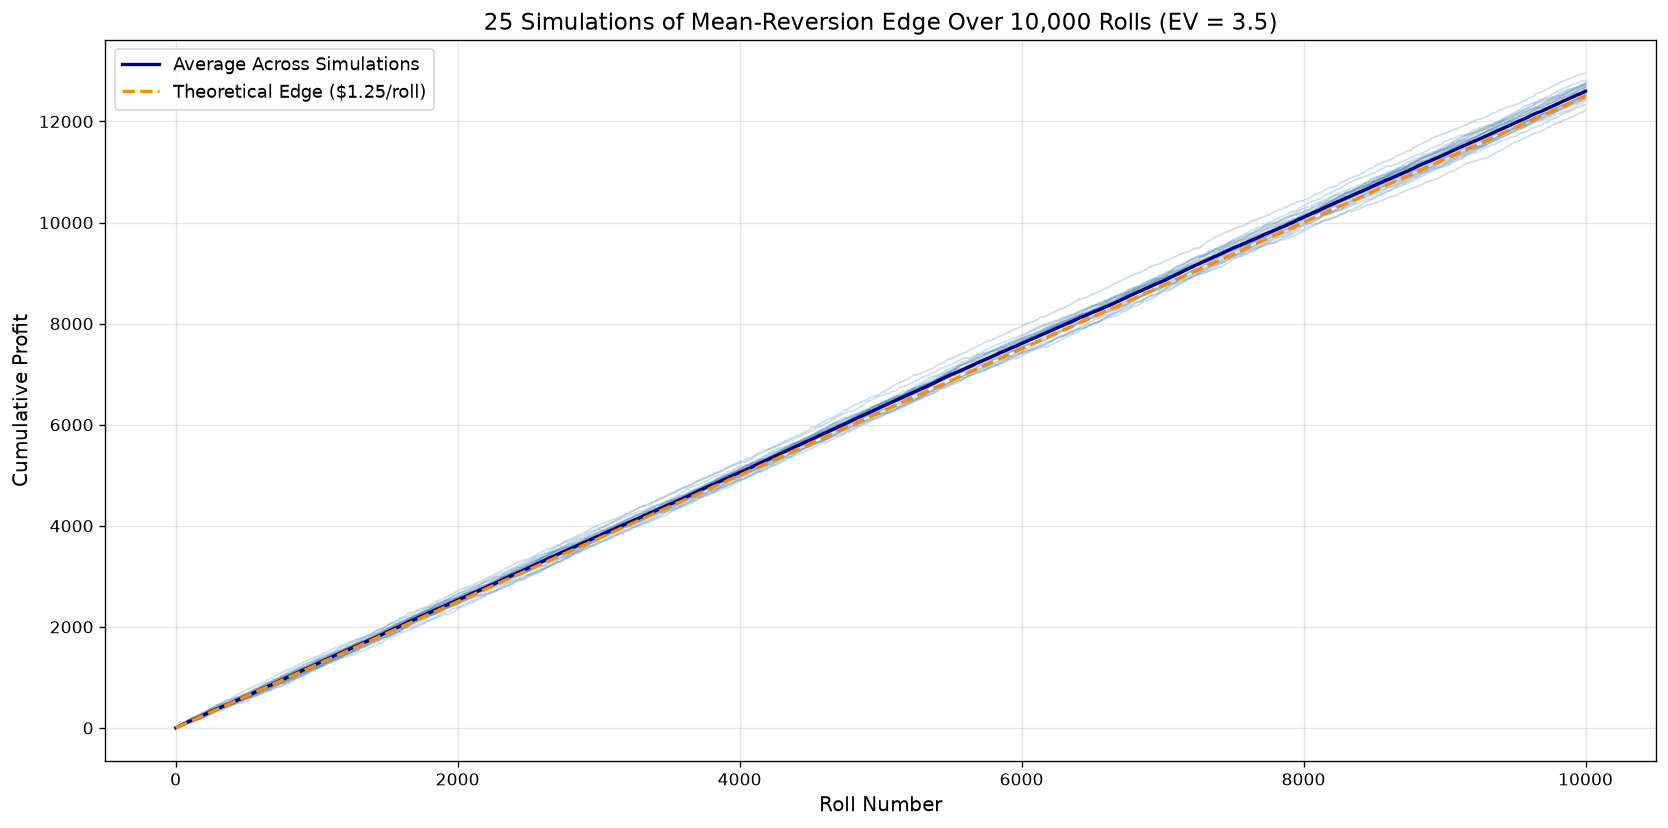

Profit Factor:       5.34
Win Rate:            70.14%
Regression Alpha:    $1.2598 per roll (Beta = 0.0022)
Excess Return Alpha: $1.2561 per roll


In [1]:
import numpy as np
import matplotlib.pyplot as plt 
rng = np.random.default_rng(42)
n_rolls = 10_000
n_sims = 25
rolls = rng.integers(1,7, size=(n_sims, n_rolls))     # True dice outcomes (EV = 3.5)
quotes = rng.uniform(1.0, 6.0, size=(n_sims, n_rolls))    # Simulated market prices offered each roll

# Buy (+1) if quote < 3.5, Sell (-1) if quote > 3.5
position = np.where(quotes < 3.5, 1, -1) 
pnl = position * (rolls - quotes)

# Cumulative P&L across rolls (axis=1) for every simulation
cum_pnl = np.cumsum(pnl, axis=1)
x = np.arange(1, n_rolls + 1)

# Enlarge figure size (width=14 inches, height=7 inches) and higher DPI
plt.figure(figsize=(14, 7), dpi=120)

# Plot all 25 simulation paths faintly, plus the average and theoretical edge
plt.plot(x, cum_pnl.T, color="steelblue", alpha=0.25, linewidth=1)
plt.plot(x, cum_pnl.mean(axis=0), color="navy", linewidth=2, label="Average Across Simulations")
plt.plot(x, x * 1.25, "--", color="darkorange", linewidth=2, label="Theoretical Edge ($1.25/roll)")

plt.xlabel("Roll Number", fontsize=12)
plt.ylabel("Cumulative Profit", fontsize=12)
plt.title(f"{n_sims} Simulations of Mean-Reversion Edge Over {n_rolls:,} Rolls (EV = 3.5)", fontsize=14)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# Flatten all simulated rolls into a single 1D array of trades
all_pnl = pnl.ravel()

# 1. Profit Factor: Gross Wins / Gross Losses
gross_profit = all_pnl[all_pnl > 0].sum()
gross_loss = np.abs(all_pnl[all_pnl < 0].sum())
profit_factor = gross_profit / gross_loss

# 2. Alpha vs. Passive Benchmark (e.g., always buying every roll: rolls - quotes)
benchmark_pnl = (rolls - quotes).ravel()

# Linear regression: strategy_pnl = alpha + beta * benchmark_pnl
beta, alpha = np.polyfit(benchmark_pnl, all_pnl, 1)

# Simple excess return per roll (Strategy EV - Benchmark EV)
excess_alpha = all_pnl.mean() - benchmark_pnl.mean()

print(f"Profit Factor:       {profit_factor:.2f}")
print(f"Win Rate:            {(all_pnl > 0).mean():.2%}")
print(f"Regression Alpha:    ${alpha:.4f} per roll (Beta = {beta:.4f})")
print(f"Excess Return Alpha: ${excess_alpha:.4f} per roll")